# NLP Lab Assignment 8 — Spell Correction + Midsem Programs

This notebook covers both tasks stated in `NLP-Lab-Assignment-8-2026.pdf`:

1. Programmatic solutions to the five questions in the supplied NLP midsemester paper.
2. A noisy-channel spell corrector using `count_1edit.txt`, `count_unigram.txt`, and `spell-errors.txt`, with measured top-1 correction accuracy.

## Expected folder layout

Keep this notebook in `Assignment8/` (or update `DATA_DIR` below):

```text
Assignment8/
├── NLP_Assignment8_Solutions.ipynb
└── Spell-Correction/
    ├── count_1edit.txt
    ├── count_unigram.txt
    └── spell-errors.txt
```

The three `.txt` files are not embedded in this notebook. The spell-correction section detects them at runtime and prints a useful message if the folder or files are missing.

## 0. Imports and paths

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from math import log, sqrt, exp
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works if the notebook is launched from Assignment8/ or from inside Spell-Correction/.
possible_dirs = [Path("Spell-Correction"), Path(".")]
DATA_DIR = next((p for p in possible_dirs if (p / "count_unigram.txt").exists()), Path("Spell-Correction"))
print("Spell-correction data directory:", DATA_DIR.resolve())

Spell-correction data directory: C:\Users\asus\OneDrive\Desktop\NLP LAB\Assignment8\Spell-Correction


# Part A — Midsem question programs

## Q1. Finite-state transducer for English noun singular/plural

Rules in the question:

- Singular: copy the stem and mark it `+N+SG` in the lexical representation.
- Plural: append `es` if the stem ends in `s`, `x`, `z`, `ch`, or `sh`; otherwise append `s`.

The small implementation below supports generation (lexical form → surface word) and analysis (surface word → possible lexical analyses). The transition table makes the stem-class decision explicit.

In [2]:
EXCEPTION_ENDINGS = ("s", "x", "z", "ch", "sh")

FST_TRANSITIONS = pd.DataFrame([
    ("q0", "stem characters", "q1", "copy characters"),
    ("q1", "+N+SG", "qf", "emit nothing (singular stem unchanged)"),
    ("q1", "+N+PL", "q_regular", "inspect stem ending"),
    ("q_regular", "stem ends s/x/z/ch/sh", "qf", "emit es"),
    ("q_regular", "otherwise", "qf", "emit s"),
], columns=["State", "Input / condition", "Next state", "Output / action"])
FST_TRANSITIONS

,State,Input / condition,Next state,Output / action
0,q0,stem characters,q1,copy characters
1,q1,+N+SG,qf,emit nothing (singular stem unchanged)
2,q1,+N+PL,q_regular,inspect stem ending
3,q_regular,stem ends s/x/z/ch/sh,qf,emit es
4,q_regular,otherwise,qf,emit s


In [3]:
def generate_noun(stem: str, number: str) -> str:
    """Generate a surface noun from a stem and number ('SG' or 'PL')."""
    stem = stem.strip()
    number = number.upper().replace("+", "")
    if number in {"SG", "N+SG"}:
        return stem
    if number in {"PL", "N+PL"}:
        return stem + ("es" if stem.lower().endswith(EXCEPTION_ENDINGS) else "s")
    raise ValueError("number must be 'SG' or 'PL'")


def analyze_noun(surface: str):
    """Return analyses valid under the assignment's spelling rules."""
    surface = surface.strip()
    analyses = []
    # A singular surface form is always a valid analysis in this simplified FST.
    analyses.append((surface, "+N+SG"))
    # Find plural stems by removing the possible suffix and checking generation.
    for suffix in ("es", "s"):
        if surface.lower().endswith(suffix) and len(surface) > len(suffix):
            stem = surface[:-len(suffix)]
            if generate_noun(stem, "PL").lower() == surface.lower():
                analyses.append((stem, "+N+PL"))
    # Keep unique analyses in order.
    return list(dict.fromkeys(analyses))

examples = ["cat", "bus", "box", "quiz", "church", "dish"]
print("Generation:")
for stem in examples:
    print(f"{stem:8} SG={generate_noun(stem, 'SG'):10} PL={generate_noun(stem, 'PL')}")
print("\nAnalysis of 'boxes':", analyze_noun("boxes"))

Generation:
cat      SG=cat        PL=cats
bus      SG=bus        PL=buses
box      SG=box        PL=boxes
quiz     SG=quiz       PL=quizes
church   SG=church     PL=churches
dish     SG=dish       PL=dishes

Analysis of 'boxes': [('boxes', '+N+SG'), ('box', '+N+PL'), ('boxe', '+N+PL')]


**FST interpretation:** the `+N` feature identifies a noun; `+SG` leaves the stem unchanged; `+PL` selects the suffix according to the final-character class. This captures the rule set in the exam question rather than every irregular plural in English.

## Q2. WordPiece algorithm — two merges, then tokenize `newest`

The corpus is entered exactly as the five lines in the question. Initial tokens are characters; non-initial characters use the WordPiece `##` continuation marker. Each merge chooses the adjacent pair maximizing `frequency(pair) / (frequency(left) × frequency(right))`. The program prints both merges and then greedily tokenizes `newest` using the learned vocabulary.

In [4]:
corpus_lines = [
    "low lower low lower lowest",
    "low lowest low lowest",
    "low new",
    "new new newer newer",
    "new",
]
word_counts = Counter(word for line in corpus_lines for word in line.split())
print("Corpus word frequencies:", dict(word_counts))


def initial_wordpiece_tokens(word):
    if not word:
        return []
    return [word[0]] + ["##" + ch for ch in word[1:]]


def merge_wordpiece_pair(tokenized_words, pair):
    left, right = pair
    # Preserve the prefix status of the left token; strip ## from the continuation token.
    right_text = right[2:] if right.startswith("##") else right
    merged = left + right_text
    new_tokenized = []
    for tokens, count in tokenized_words:
        out, i = [], 0
        while i < len(tokens):
            if i + 1 < len(tokens) and (tokens[i], tokens[i+1]) == pair:
                out.append(merged)
                i += 2
            else:
                out.append(tokens[i])
                i += 1
        new_tokenized.append((out, count))
    return new_tokenized, merged


def train_wordpiece(word_counts, n_merges=2):
    tokenized = [(initial_wordpiece_tokens(w), count) for w, count in word_counts.items()]
    merges, vocab = [], set(t for toks, _ in tokenized for t in toks)
    for _ in range(n_merges):
        pair_counts = Counter()
        token_counts = Counter()
        for toks, count in tokenized:
            for token in toks:
                token_counts[token] += count
            for pair in zip(toks, toks[1:]):
                pair_counts[pair] += count
        scores = {
            pair: pair_count / (token_counts[pair[0]] * token_counts[pair[1]])
            for pair, pair_count in pair_counts.items()
            if token_counts[pair[0]] and token_counts[pair[1]]
        }
        if not scores:
            break
        best_pair = max(scores, key=lambda p: (scores[p], pair_counts[p], p))
        tokenized, merged = merge_wordpiece_pair(tokenized, best_pair)
        merges.append((best_pair, merged, pair_counts[best_pair], scores[best_pair]))
        vocab.add(merged)
    vocab.update(t for toks, _ in tokenized for t in toks)
    return merges, vocab, tokenized


def wordpiece_tokenize(word, vocab):
    """Greedy longest-match WordPiece tokenization; returns [UNK] if no full segmentation."""
    pieces, start = [], 0
    while start < len(word):
        end = len(word)
        match = None
        while end > start:
            chunk = word[start:end]
            token = chunk if start == 0 else "##" + chunk
            if token in vocab:
                match = (token, end)
                break
            end -= 1
        if match is None:
            return ["[UNK]"]
        pieces.append(match[0])
        start = match[1]
    return pieces

merges, wp_vocab, trained_words = train_wordpiece(word_counts, n_merges=2)
for i, (pair, merged, count, score) in enumerate(merges, 1):
    print(f"Merge {i}: {pair[0]} + {pair[1]} -> {merged}; pair count={count}; score={score:.6f}")
print("WordPiece tokenization of 'newest':", wordpiece_tokenize("newest", wp_vocab))
print("Learned vocabulary:", sorted(wp_vocab))

Corpus word frequencies: {'low': 5, 'lower': 2, 'lowest': 3, 'new': 4, 'newer': 2}
Merge 1: ##s + ##t -> ##st; pair count=3; score=0.333333
Merge 2: l + ##o -> lo; pair count=10; score=0.100000
WordPiece tokenization of 'newest': ['n', '##e', '##w', '##e', '##st']
Learned vocabulary: ['##e', '##o', '##r', '##s', '##st', '##t', '##w', 'l', 'lo', 'n']


**Note:** WordPiece implementations can differ in tie-breaking and vocabulary conventions. This cell explicitly states the scoring formula and deterministic tie-break used, so the result can be reproduced and discussed in a lab report.

## Q3. Raw-count TF × unsmoothed IDF and closest sentences

In [5]:
sentences = [
    "cat dog animal",
    "cat cat pet",
    "dog pet animal",
    "cat dog pet",
]
tokenized_sentences = [s.split() for s in sentences]
vocabulary = sorted(set(word for sent in tokenized_sentences for word in sent))
N = len(sentences)
df = {word: sum(word in sent for sent in tokenized_sentences) for word in vocabulary}
idf = {word: log(N / df[word]) for word in vocabulary}  # unsmoothed IDF

tfidf = np.array([
    [sent.count(word) * idf[word] for word in vocabulary]
    for sent in tokenized_sentences
], dtype=float)

tfidf_table = pd.DataFrame(tfidf, index=[f"S{i+1}" for i in range(N)], columns=vocabulary)
print("Document frequencies:", df)
print("IDF values:", {w: round(v, 6) for w, v in idf.items()})
print("\nTF-IDF vectors (raw TF):")
display(tfidf_table.round(6))


def cosine(a, b):
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.dot(a, b) / denom) if denom else 0.0

similarities = []
for i in range(N):
    for j in range(i + 1, N):
        similarities.append((f"S{i+1}", f"S{j+1}", cosine(tfidf[i], tfidf[j])))
similarity_table = pd.DataFrame(similarities, columns=["Sentence 1", "Sentence 2", "Cosine similarity"])
display(similarity_table.sort_values("Cosine similarity", ascending=False).reset_index(drop=True).round(6))
print("Closest pair:", max(similarities, key=lambda x: x[2]))

Document frequencies: {'animal': 2, 'cat': 3, 'dog': 3, 'pet': 3}
IDF values: {'animal': 0.693147, 'cat': 0.287682, 'dog': 0.287682, 'pet': 0.287682}

TF-IDF vectors (raw TF):


,animal,cat,dog,pet
S1,0.693147,0.287682,0.287682,0.000000
S2,0.000000,0.575364,0.000000,0.287682
S3,0.693147,0.000000,0.287682,0.287682
S4,0.000000,0.287682,0.287682,0.287682


,Sentence 1,Sentence 2,Cosine similarity
0,S1,S3,0.871882
1,S2,S4,0.774597
2,S3,S4,0.413308
3,S1,S4,0.413308
4,S1,S2,0.320147
5,S2,S3,0.160074


Closest pair: ('S1', 'S3', 0.871882070542168)


**Formula used:** `TF(t, d)` is the raw number of occurrences in sentence `d`; `IDF(t) = ln(N / df(t))`; `TF-IDF = TF × IDF`. The closest pair is chosen by cosine similarity between sentence vectors.

## Q4. Bernoulli Naive Bayes spam classifier for E8 = (0, 0, 0)

In [6]:
spam_data = pd.DataFrame([
    (1, 1, 1, "Spam"),
    (1, 1, 0, "Spam"),
    (1, 0, 1, "Spam"),
    (0, 1, 1, "Spam"),
    (0, 0, 1, "NotSpam"),
    (0, 1, 0, "NotSpam"),
    (1, 0, 0, "NotSpam"),
], columns=["free", "win", "offer", "class"])
new_email = {"free": 0, "win": 0, "offer": 0}
classes = list(spam_data["class"].unique())
N = len(spam_data)
results = []
for cls in classes:
    subset = spam_data[spam_data["class"] == cls]
    prior = len(subset) / N
    likelihoods = {
        feat: (subset[feat].eq(value).sum() / len(subset))
        for feat, value in new_email.items()
    }
    joint = prior * np.prod(list(likelihoods.values()))
    results.append({"Class": cls, "Prior": prior, **{f"P({feat}={value}|class)": likelihoods[feat] for feat, value in new_email.items()}, "Unnormalized posterior": joint})
nb_table = pd.DataFrame(results).set_index("Class")
display(nb_table.round(6))
normalizer = nb_table["Unnormalized posterior"].sum()
nb_table["Normalized posterior"] = nb_table["Unnormalized posterior"] / normalizer
display(nb_table[["Unnormalized posterior", "Normalized posterior"]].round(6))
print("Predicted class for E8:", nb_table["Unnormalized posterior"].idxmax())

,Prior,P(free=0|class),P(win=0|class),P(offer=0|class),Unnormalized posterior
Class,,,,,
Spam,0.571429,0.250000,0.250000,0.250000,0.008929
NotSpam,0.428571,0.666667,0.666667,0.666667,0.126984


,Unnormalized posterior,Normalized posterior
Class,,
Spam,0.008929,0.065693
NotSpam,0.126984,0.934307


Predicted class for E8: NotSpam


**Model assumption:** this is Bernoulli Naive Bayes because each feature says whether a word is present (`1`) or absent (`0`). No smoothing is applied, matching the direct computation requested in the question.

## Q5. Kneser–Ney smoothing with discount d = 0.5

In [7]:
kn_sentences = [
    "I like NLP",
    "I like AI",
    "You like NLP",
    "You love AI",
    "We love NLP",
]
tokens_by_sentence = [s.split() for s in kn_sentences]
bigram_counts = Counter()
context_counts = Counter()
predecessors = defaultdict(set)
followers = defaultdict(set)
for tokens in tokens_by_sentence:
    for a, b in zip(tokens, tokens[1:]):
        bigram_counts[(a, b)] += 1
        context_counts[a] += 1
        predecessors[b].add(a)
        followers[a].add(b)

n_bigram_types = len(bigram_counts)
continuation_prob = {w: len(predecessors[w]) / n_bigram_types for w in set(t for s in tokens_by_sentence for t in s)}
discount = 0.5

def p_kneser_ney(word, context):
    c_hw = bigram_counts[(context, word)]
    c_h = context_counts[context]
    if c_h == 0:
        return continuation_prob.get(word, 0.0)
    discounted = max(c_hw - discount, 0) / c_h
    lambda_h = discount * len(followers[context]) / c_h
    return discounted + lambda_h * continuation_prob.get(word, 0.0)

print("Bigram counts:", dict(bigram_counts))
print("Number of distinct bigram types:", n_bigram_types)
print("Continuation probabilities:", {w: round(p, 6) for w, p in continuation_prob.items()})
for word, context in [("AI", "love"), ("NLP", "like")]:
    print(f"P_KN({word} | {context}) = {p_kneser_ney(word, context):.6f}")

Bigram counts: {('I', 'like'): 2, ('like', 'NLP'): 2, ('like', 'AI'): 1, ('You', 'like'): 1, ('You', 'love'): 1, ('love', 'AI'): 1, ('We', 'love'): 1, ('love', 'NLP'): 1}
Number of distinct bigram types: 8
Continuation probabilities: {'AI': 0.25, 'NLP': 0.25, 'I': 0.0, 'like': 0.25, 'love': 0.25, 'We': 0.0, 'You': 0.0}
P_KN(AI | love) = 0.375000
P_KN(NLP | like) = 0.583333


# Part B — Noisy-channel spell correction

The spell checker uses Bayes' noisy-channel decision rule:

\[
\hat{w} = \arg\max_w P(x\mid w)P(w)
\]

where `x` is the observed misspelling, `w` is a candidate correction, `P(w)` comes from `count_unigram.txt`, and `P(x|w)` is estimated from edit-operation counts in `count_1edit.txt`. Candidate words are generated at edit distance 1 and retained only if present in the unigram vocabulary. The `spell-errors.txt` file supplies labelled typo/correct-word pairs for accuracy evaluation.

**Data-format assumption:** the edit-count file is read as `source|target count` (as in the screenshot, for example `e|i 917`). The code supports a configurable direction if your instructor defines the pair in the opposite direction.

In [8]:
# Change to "error_to_correct" only if your course's count_1edit.txt defines pairs that way.
EDIT_DIRECTION = "correct_to_error"


def parse_unigram_file(path):
    counts = {}
    if not path.exists():
        return counts
    with path.open("r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.rsplit(maxsplit=1)
            if len(parts) != 2:
                continue
            word, raw_count = parts
            try:
                count = int(raw_count.replace(",", ""))
            except ValueError:
                continue
            counts[word.lower()] = counts.get(word.lower(), 0) + count
    return counts


def parse_edit_counts(path):
    counts = Counter()
    if not path.exists():
        return counts
    with path.open("r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.rsplit(maxsplit=1)
            if len(parts) != 2:
                continue
            operation, raw_count = parts
            try:
                n = int(raw_count.replace(",", ""))
            except ValueError:
                continue
            if "|" not in operation:
                continue
            left, right = operation.split("|", 1)
            left, right = left.strip().lower(), right.strip().lower()
            if EDIT_DIRECTION == "error_to_correct":
                left, right = right, left
            counts[(left, right)] += n
    return counts


def parse_spell_errors(path):
    """Parse rows such as 'raining: rainning, raning'. A suffix *N means N occurrences."""
    pairs = []
    if not path.exists():
        return pairs
    with path.open("r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()
            if not line or ":" not in line:
                continue
            correct, typo_part = line.split(":", 1)
            correct = correct.strip().lower()
            typos = [x.strip().lower() for x in re.split(r"[,;]", typo_part) if x.strip()]
            for raw_typo in typos:
                # Some entries annotate frequency as fore*5. Preserve that frequency in evaluation.
                match = re.fullmatch(r"(.*?)\*(\d+)", raw_typo)
                if match:
                    typo = match.group(1).strip()
                    weight = int(match.group(2))
                else:
                    typo, weight = raw_typo, 1
                for _ in range(max(weight, 1)):
                    pairs.append((correct, typo))
    return pairs

unigram_counts = parse_unigram_file(DATA_DIR / "count_unigram.txt")
edit_counts = parse_edit_counts(DATA_DIR / "count_1edit.txt")
labelled_pairs = parse_spell_errors(DATA_DIR / "spell-errors.txt")
print(f"Unigram entries: {len(unigram_counts):,}")
print(f"Edit operations: {len(edit_counts):,}")
print(f"Labelled correct/typo pairs: {len(labelled_pairs):,}")
if not (unigram_counts and edit_counts and labelled_pairs):
    print("\nOne or more data files were not found or could not be parsed. Put all three files in the Spell-Correction folder and rerun this section.")

Unigram entries: 333,333
Edit operations: 1,512
Labelled correct/typo pairs: 41,718


In [9]:
import string
ALPHABET = string.ascii_lowercase


def edits1(word):
    """Generate all strings one insertion, deletion, substitution, or adjacent transposition away."""
    word = word.lower()
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]
    candidates = set()
    # deletions
    candidates.update(L + R[1:] for L, R in splits if R)
    # transpositions
    candidates.update(L + R[1] + R[0] + R[2:] for L, R in splits if len(R) > 1)
    # substitutions
    candidates.update(L + c + R[1:] for L, R in splits if R for c in ALPHABET)
    # insertions
    candidates.update(L + c + R for L, R in splits for c in ALPHABET)
    candidates.discard(word)
    return candidates


def edit_operations(correct, observed):
    """Return simple character edit operations correct -> observed using Levenshtein DP.

    Substitution key: old_char|new_char.
    Insertion key: preceding_correct_char|preceding_correct_char+inserted_char.
    Deletion key: preceding_correct_char+deleted_char|preceding_correct_char.
    Boundary insertions/deletions use an empty context.
    """
    a, b = correct.lower(), observed.lower()
    m, n = len(a), len(b)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    back = [[None] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1): dp[i][0] = i; back[i][0] = "delete"
    for j in range(1, n + 1): dp[0][j] = j; back[0][j] = "insert"
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if a[i-1] == b[j-1]:
                dp[i][j] = dp[i-1][j-1]
                back[i][j] = "match"
            else:
                options = [(dp[i-1][j-1] + 1, "substitute"), (dp[i-1][j] + 1, "delete"), (dp[i][j-1] + 1, "insert")]
                dp[i][j], back[i][j] = min(options, key=lambda z: z[0])
    ops = []
    i, j = m, n
    while i > 0 or j > 0:
        op = back[i][j]
        if op == "match":
            i -= 1; j -= 1
        elif op == "substitute":
            ops.append((a[i-1], b[j-1]))
            i -= 1; j -= 1
        elif op == "delete":
            prev = a[i-2] if i >= 2 else ""
            ops.append((prev + a[i-1], prev))
            i -= 1
        elif op == "insert":
            prev = a[i-1] if i >= 1 else ""
            ops.append((prev, prev + b[j-1]))
            j -= 1
        else:
            break
    return list(reversed(ops))


def levenshtein_distance(a, b):
    a, b = a.lower(), b.lower()
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(cur[-1] + 1, prev[j] + 1, prev[j-1] + (ca != cb)))
        prev = cur
    return prev[-1]


def build_edit_denominators(edit_counts):
    denoms = Counter()
    for (left, right), count in edit_counts.items():
        denoms[left] += count
    return denoms

edit_denoms = build_edit_denominators(edit_counts)

In [10]:
def channel_log_probability(correct, observed, edit_counts=edit_counts, edit_denoms=edit_denoms):
    """Approximate log P(observed|correct) from character edit counts with small smoothing."""
    if correct == observed:
        return 0.0
    if levenshtein_distance(correct, observed) != 1:
        # A candidate at distance > 1 gets a strong penalty; normal candidate search uses distance 1.
        return -50.0 * levenshtein_distance(correct, observed)
    ops = edit_operations(correct, observed)
    score = 0.0
    for left, right in ops:
        count = edit_counts.get((left, right), 0)
        denom = edit_denoms.get(left, 0)
        if count > 0 and denom > 0:
            probability = count / denom
        else:
            # Smoothing fallback for operations absent from the file.
            # It keeps the score finite but lets unigram frequency help rank candidates.
            probability = 1e-9
        score += log(probability)
    return score


def spell_correct(
    observed,
    unigram_counts=unigram_counts,
    edit_counts=edit_counts,
    edit_denoms=edit_denoms,
    vocab=None,
    total_unigrams=None,
):
    """Correct one misspelling using a noisy-channel score.

    Pass `vocab` and `total_unigrams` when processing many words to avoid
    rebuilding the vocabulary set and summing the counts for each typo.
    """
    observed = str(observed).lower().strip()
    if not observed:
        return None, []

    # Compute fallbacks for standalone calls. Batch evaluation supplies these once.
    if vocab is None:
        vocab = set(unigram_counts)
    if total_unigrams is None:
        total_unigrams = sum(unigram_counts.values())
    total_unigrams = total_unigrams or 1

    # Preserve an in-vocabulary word as-is rather than needlessly changing a valid word.
    if observed in vocab:
        return observed, [(observed, 0.0)]

    candidates = edits1(observed) & vocab
    if not candidates:
        return None, []

    prior_denominator = total_unigrams + len(vocab)
    scored = []
    for candidate in candidates:
        prior = (unigram_counts.get(candidate, 0) + 1) / prior_denominator
        score = log(prior) + channel_log_probability(
            candidate, observed, edit_counts, edit_denoms
        )
        scored.append((candidate, score))

    scored.sort(key=lambda z: (-z[1], z[0]))
    return scored[0][0], scored

# Quick sanity demonstration, independent of the actual files.
_demo_unigrams = {"raining": 500, "training": 700, "running": 900, "rainy": 120}
_demo_edit_counts = Counter({("n", "nn"): 20, ("i", "a"): 5, ("i", "e"): 7})
_demo_denoms = build_edit_denominators(_demo_edit_counts)
_demo_vocab = set(_demo_unigrams)
_demo_total = sum(_demo_unigrams.values())
print("Demo typo 'rainning' ->", spell_correct(
    "rainning", _demo_unigrams, _demo_edit_counts, _demo_denoms,
    _demo_vocab, _demo_total
)[0])

Demo typo 'rainning' -> raining


### Accuracy evaluation

Each entry in `spell-errors.txt` is read as one correct word followed by one or more misspellings. For every labelled typo, the program predicts a word and checks whether it matches the correct word. Accuracy is **top-1 labelled typo accuracy**, not an evaluation on a separate hidden test split. If the provided file is small or is also used to develop the model, note that limitation in the report.

**Performance note:** The evaluator constructs the vocabulary set, edit-operation denominators, and total unigram frequency once per evaluation pass, then reuses them for every typo. If the error file expands frequency annotations such as `fore*5`, progress is printed every 1,000 evaluated pairs.

In [11]:
def evaluate_spell_checker(labelled_pairs, unigram_counts, edit_counts):
    """Evaluate top-1 spell-correction accuracy with precomputed batch values."""
    if not unigram_counts or not edit_counts or not labelled_pairs:
        print("No evaluation performed. Check the three Spell-Correction data files and DATA_DIR.")
        return pd.DataFrame(columns=[
            "Correct word", "Misspelling", "Prediction", "Correct?", "Candidates considered"
        ]), float("nan")

    # Expensive corpus-wide work is done once, not once per misspelling.
    edit_denoms = build_edit_denominators(edit_counts)
    vocab = set(unigram_counts)
    total_unigrams = sum(unigram_counts.values()) or 1

    rows = []
    for index, (correct, typo) in enumerate(labelled_pairs, start=1):
        prediction, ranked = spell_correct(
            typo,
            unigram_counts=unigram_counts,
            edit_counts=edit_counts,
            edit_denoms=edit_denoms,
            vocab=vocab,
            total_unigrams=total_unigrams,
        )
        rows.append({
            "Correct word": correct,
            "Misspelling": typo,
            "Prediction": prediction,
            "Correct?": prediction == correct,
            "Candidates considered": len(ranked),
        })

        # Occasional progress indicator for large, frequency-expanded error lists.
        if index % 1000 == 0:
            print(f"Evaluated {index:,}/{len(labelled_pairs):,} labelled misspellings...")

    result = pd.DataFrame(rows)
    accuracy = float(result["Correct?"].mean()) if len(result) else float("nan")
    if len(result):
        print(f"Vocabulary size: {len(vocab):,}")
        print(f"Labelled pairs evaluated: {len(result):,}")
        print(f"Top-1 accuracy: {accuracy:.2%}")
        display(result.head(30))
    else:
        print("No labelled typo pairs available.")
    return result, accuracy


# Run evaluation automatically when all three source files were parsed.
if unigram_counts and edit_counts and labelled_pairs:
    spell_results, spell_accuracy = evaluate_spell_checker(
        labelled_pairs, unigram_counts, edit_counts
    )
else:
    spell_results = pd.DataFrame(columns=[
        "Correct word", "Misspelling", "Prediction", "Correct?", "Candidates considered"
    ])
    spell_accuracy = float("nan")
    print("Spell-checker evaluation skipped because one or more data files are missing or empty.")

Evaluated 1,000/41,718 labelled misspellings...
Evaluated 2,000/41,718 labelled misspellings...
Evaluated 3,000/41,718 labelled misspellings...
Evaluated 4,000/41,718 labelled misspellings...
Evaluated 5,000/41,718 labelled misspellings...
Evaluated 6,000/41,718 labelled misspellings...
Evaluated 7,000/41,718 labelled misspellings...
Evaluated 8,000/41,718 labelled misspellings...
Evaluated 9,000/41,718 labelled misspellings...
Evaluated 10,000/41,718 labelled misspellings...
Evaluated 11,000/41,718 labelled misspellings...
Evaluated 12,000/41,718 labelled misspellings...
Evaluated 13,000/41,718 labelled misspellings...
Evaluated 14,000/41,718 labelled misspellings...
Evaluated 15,000/41,718 labelled misspellings...
Evaluated 16,000/41,718 labelled misspellings...
Evaluated 17,000/41,718 labelled misspellings...
Evaluated 18,000/41,718 labelled misspellings...
Evaluated 19,000/41,718 labelled misspellings...
Evaluated 20,000/41,718 labelled misspellings...
Evaluated 21,000/41,718 label

,Correct word,Misspelling,Prediction,Correct?,Candidates considered
0,raining,rainning,rainning,False,1
1,raining,raning,ranking,False,26
2,writings,writtings,writings,True,2
3,disparagingly,disparingly,None,False,0
4,yellow,yello,yello,False,1
5,four,forer,forer,False,1
6,four,fours,fours,False,1
7,four,fuore,furore,False,9
8,four,fore,fore,False,1
9,four,fore,fore,False,1


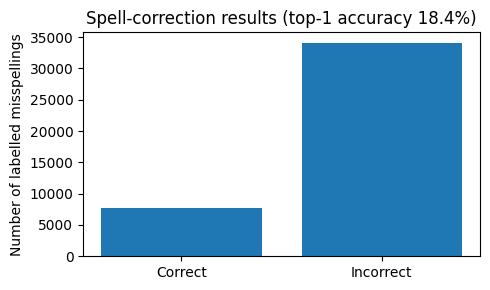

In [12]:
# Optional visualization of evaluated labelled errors.
if len(spell_results):
    counts = spell_results["Correct?"].value_counts().reindex([True, False], fill_value=0)
    plt.figure(figsize=(5, 3))
    plt.bar(["Correct", "Incorrect"], [counts[True], counts[False]])
    plt.title(f"Spell-correction results (top-1 accuracy {spell_accuracy:.1%})")
    plt.ylabel("Number of labelled misspellings")
    plt.tight_layout()
    plt.show()

## Report checklist

- **Q1:** Include the FST transition table and examples showing regular and exceptional plural suffixes.
- **Q2:** Include the exact two merges printed by the notebook and the resulting tokenization of `newest`. Mention the merge-score formula and tie-breaking convention.
- **Q3:** Include the TF-IDF vector table, cosine-similarity table, and closest pair.
- **Q4:** Include class priors, each Bernoulli likelihood for E8, unnormalized scores, normalized posterior probabilities, and the prediction.
- **Q5:** Show `P_cont(AI)` and `P_cont(NLP)`, the two discounting terms, and the final Kneser–Ney probabilities.
- **Spell correction:** State the noisy-channel equation, document the interpretation of `count_1edit.txt`, show the accuracy output, and discuss failures. The provided assignment materials do not define a separate train/dev/test split for spell correction, so the notebook evaluates on the labelled typo pairs in `spell-errors.txt`.

### Reproducibility

Run the notebook top-to-bottom. If the data files are not in `Spell-Correction/`, update `DATA_DIR` in section 0. The midsem solutions are self-contained and do not need the spell-correction files.